# Lab 2.2 — Toán tử điểm ảnh và lọc tuyến tính
Chạy **Run All**. Quy trình: **đọc ảnh RGB → toán tử điểm / lọc lân cận → so sánh → lưu kết quả**.
Notebook sử dụng các hàm trong `image_processing.py`. Chọn kernel đã cài `requirements.txt`.

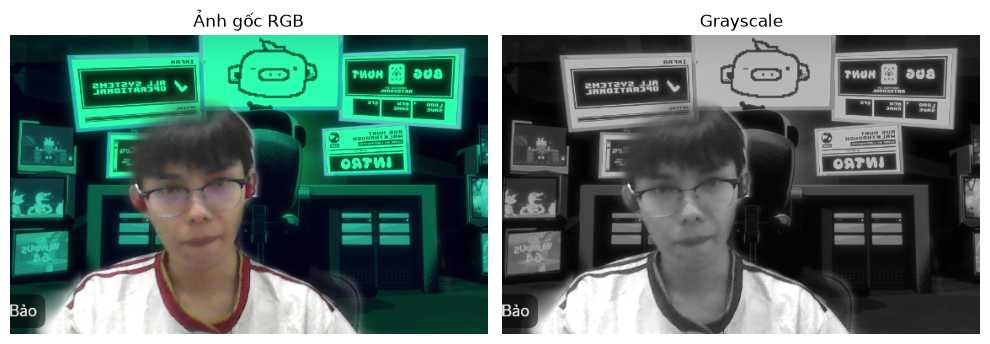

Shape: (355, 567, 3) | dtype: uint8 | min/max: 0 255


In [1]:
from pathlib import Path
import sys
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
%matplotlib inline
LAB = Path.cwd().resolve()
if not (LAB / 'image_processing.py').exists(): LAB = LAB / 'Lab_2.2'
if not (LAB / 'image_processing.py').exists(): raise FileNotFoundError('Mở notebook từ Lab_2.2 hoặc thư mục gốc repo')
sys.path.insert(0, str(LAB))
from image_processing import *
image = read_rgb(LAB / 'images/sample.jpg')
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
def show(items, columns=3, title=None):
    rows = (len(items) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 3.8 * rows), squeeze=False)
    for ax, (name, values) in zip(axes.ravel(), items):
        ax.imshow(values, cmap='gray', vmin=0, vmax=255)
        ax.set_title(name); ax.axis('off')
    for ax in axes.ravel()[len(items):]: ax.axis('off')
    if title: fig.suptitle(title)
    plt.tight_layout(); plt.show()
show([('Ảnh gốc RGB', image), ('Grayscale', gray)], columns=2)
print('Shape:', image.shape, '| dtype:', image.dtype, '| min/max:', image.min(), image.max())

## 1. Thay đổi độ sáng
$g=\mathrm{clip}(f+\beta,0,255)$. Cộng beta dương làm sáng, beta âm làm tối. Những vùng chạm 0 hoặc 255 mất thông tin do clipping.

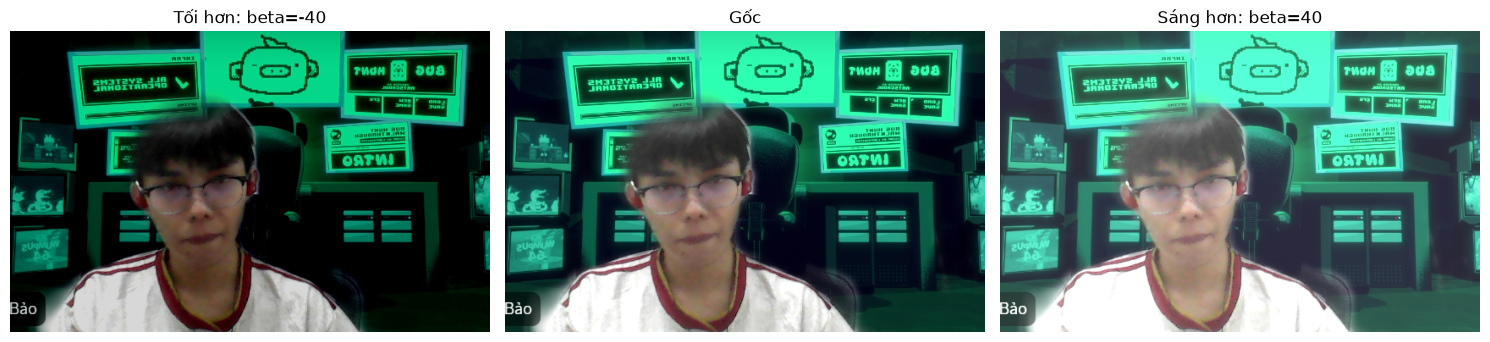

In [2]:
show([('Tối hơn: beta=-40', brightness(image,-40)), ('Gốc',image), ('Sáng hơn: beta=40',brightness(image,40))])

## 2. Thay đổi độ tương phản
$g=\mathrm{clip}(\alpha f,0,255)$. Theo yêu cầu đề, nhân trực tiếp với hằng số; alpha > 1 tăng độ dốc ánh xạ, 0 < alpha < 1 giảm độ dốc. Phép này cũng làm thay đổi độ sáng trung bình.

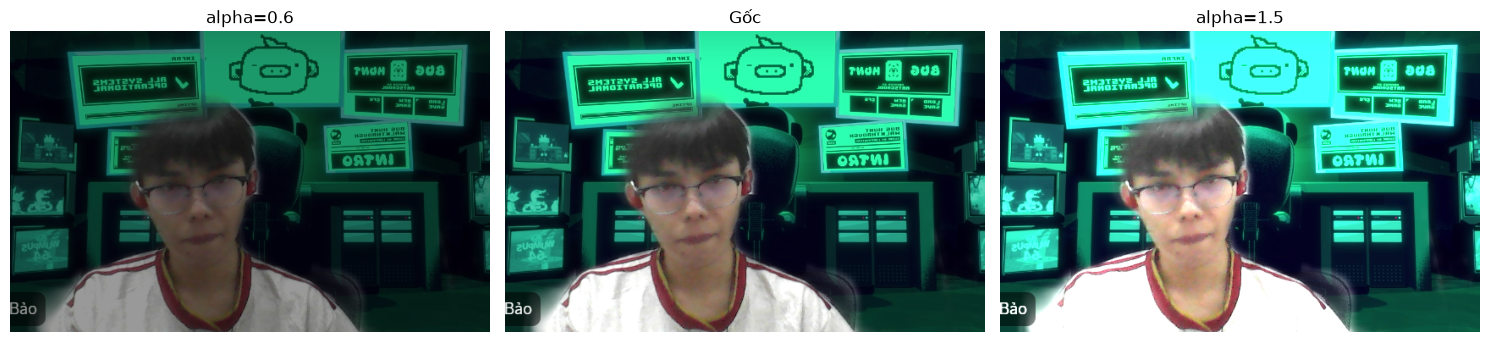

In [3]:
show([('alpha=0.6',contrast(image,0.6)),('Gốc',image),('alpha=1.5',contrast(image,1.5))])

## 3. Biến đổi âm bản
$g=255-f$. Giá trị sáng thành tối và ngược lại; thực hiện độc lập trên các kênh RGB.

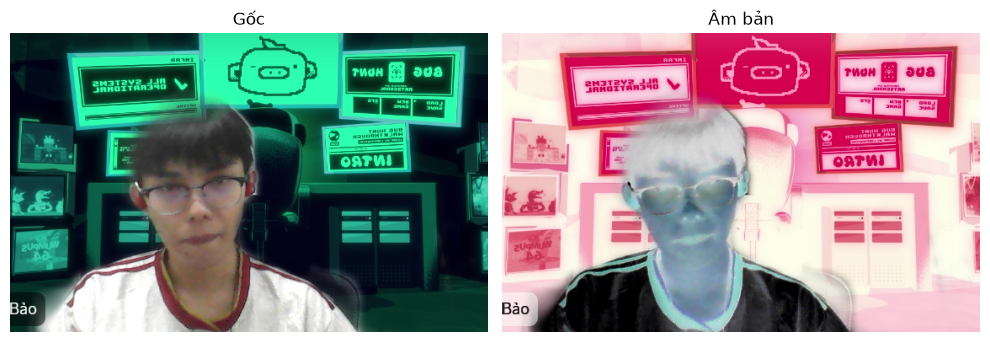

In [4]:
show([('Gốc',image),('Âm bản',negative(image))],columns=2)

## 4. Cắt ngưỡng
Chuyển grayscale trước khi so sánh. $g=255$ nếu $f \geq T$, ngược lại $g=0$. Thay đổi T để quan sát vùng được giữ lại.

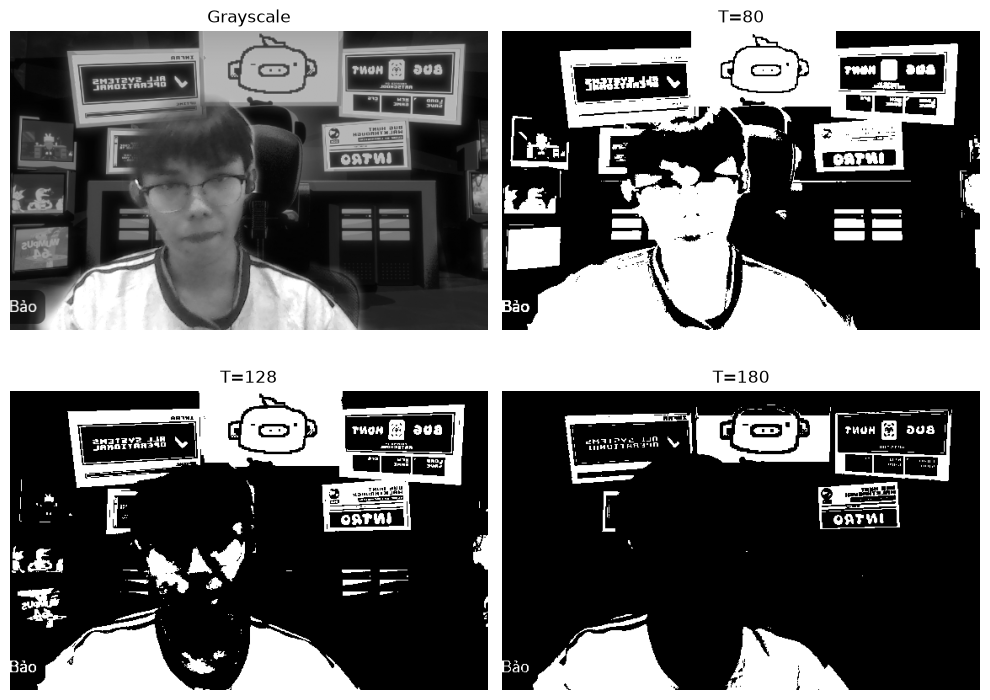

In [5]:
show([('Grayscale',gray),('T=80',threshold(image,80)),('T=128',threshold(image,128)),('T=180',threshold(image,180))],columns=2)

### Đồ thị ánh xạ và histogram
Đồ thị thể hiện mỗi mức đầu vào được biến đổi thế nào. Histogram dưới đây dùng grayscale để so sánh phân bố mức sáng.

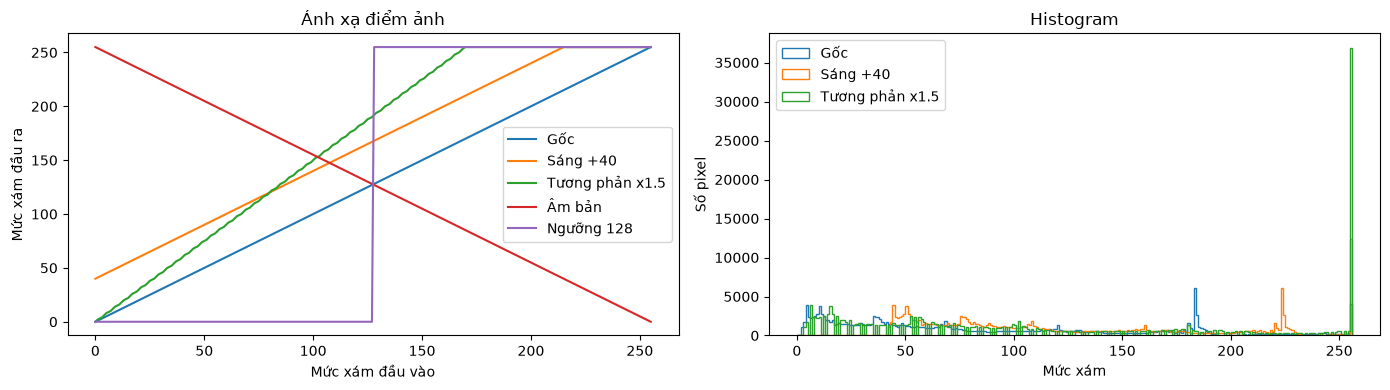

In [6]:
x=np.arange(256,dtype=np.uint8)
fig,axes=plt.subplots(1,2,figsize=(14,4))
for name,y in [('Gốc',x),('Sáng +40',brightness(x,40)),('Tương phản x1.5',contrast(x,1.5)),('Âm bản',negative(x)),('Ngưỡng 128',threshold(x))]:
    axes[0].plot(x,y,label=name)
axes[0].set(xlabel='Mức xám đầu vào',ylabel='Mức xám đầu ra',title='Ánh xạ điểm ảnh'); axes[0].legend()
for name,values in [('Gốc',gray),('Sáng +40',brightness(gray,40)),('Tương phản x1.5',contrast(gray,1.5))]:
    axes[1].hist(values.ravel(),bins=256,range=(0,256),histtype='step',label=name)
axes[1].set(xlabel='Mức xám',ylabel='Số pixel',title='Histogram'); axes[1].legend()
plt.tight_layout(); plt.show()

## 5. Lọc trung bình
Mỗi pixel là trung bình lân cận: kernel k×k có trọng số 1/k². Kernel càng lớn ảnh càng mờ. Dùng biên phản chiếu, không thêm viền đen.

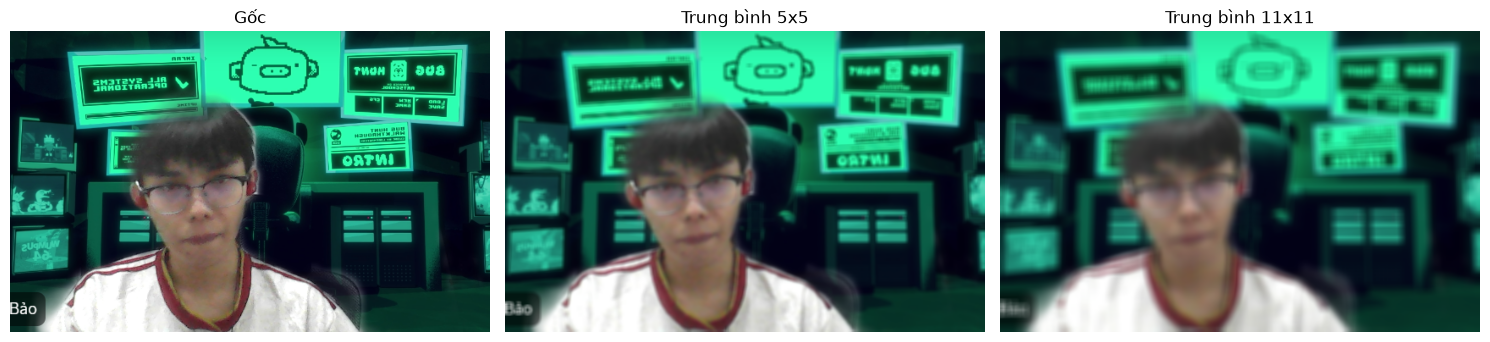

In [7]:
show([('Gốc',image),('Trung bình 5x5',mean_filter(image,5)),('Trung bình 11x11',mean_filter(image,11))])

## 6. Lọc Gaussian
$K(x,y) \propto \exp(-(x^2+y^2)/(2\sigma^2))$, chuẩn hóa tổng trọng số bằng 1. Pixel gần tâm được ưu tiên hơn; sigma điều khiển độ lan rộng.

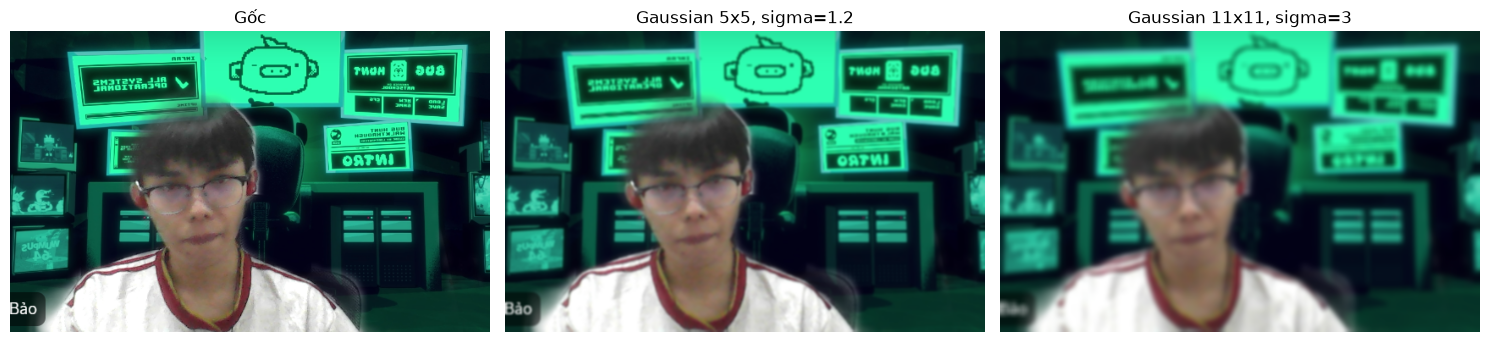

In [8]:
show([('Gốc',image),('Gaussian 5x5, sigma=1.2',gaussian_filter(image,5,1.2)),('Gaussian 11x11, sigma=3',gaussian_filter(image,11,3))])

## 7. Làm sắc nét
Kernel có tâm dương, lân cận âm, tổng trọng số bằng 1. Tăng cường biến thiên ở cạnh; đồng thời có thể tăng nhiễu và tạo vùng bão hòa. `filter2D` thực hiện correlation; vì các kernel ở đây đối xứng nên kết quả tương đương convolution.

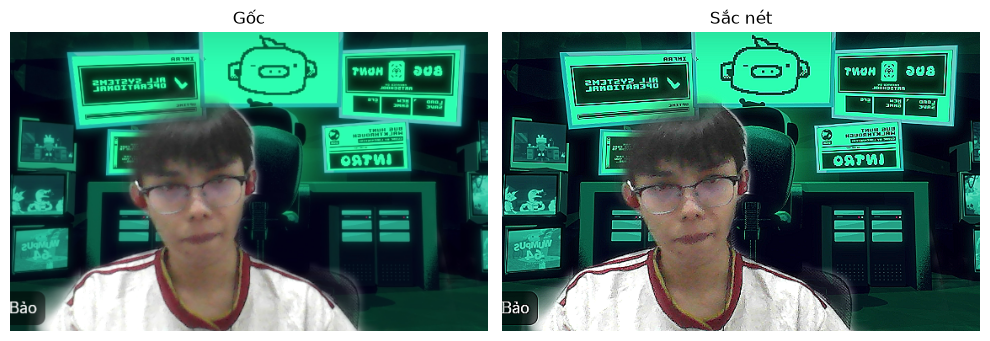

In [9]:
show([('Gốc',image),('Sắc nét',sharpen(image))],columns=2)

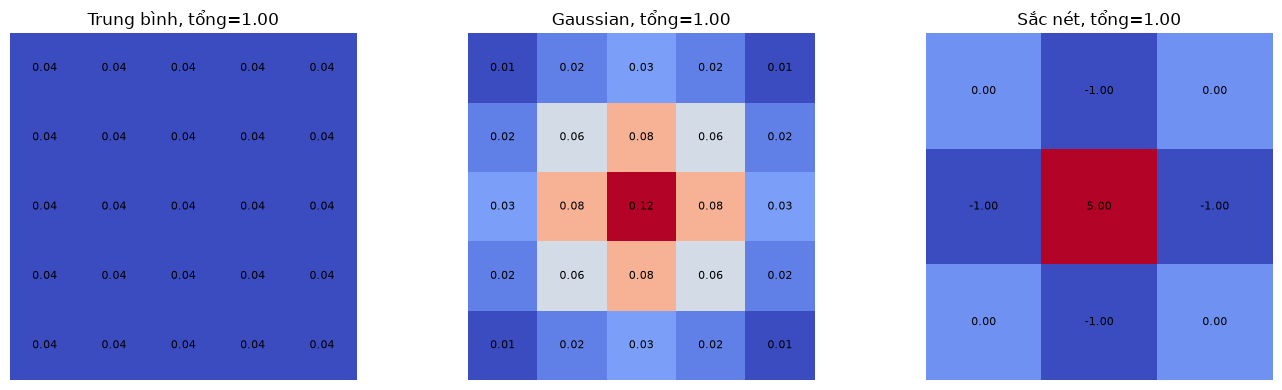

In [10]:
v=cv2.getGaussianKernel(5,1.2)
kernels=[('Trung bình',np.ones((5,5))/25),('Gaussian',v@v.T),('Sắc nét',SHARPEN_KERNEL)]
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(name,kernel) in zip(axes,kernels):
    ax.imshow(kernel,cmap='coolwarm')
    for (r,col),value in np.ndenumerate(kernel): ax.text(col,r,f'{value:.2f}',ha='center',va='center',fontsize=8)
    ax.set_title(f'{name}, tổng={kernel.sum():.2f}'); ax.axis('off')
plt.tight_layout(); plt.show()

## 8. So sánh trên ảnh nhiễu có thể tái lập
Sinh nhiễu Gaussian với seed 42, độ lệch chuẩn 15. Làm mượt có thể giảm nhiễu nhưng cũng mất chi tiết; sắc nét có thể khuếch đại nhiễu. Minh họa trên một ảnh không đủ kết luận phương pháp nào luôn tốt hơn.

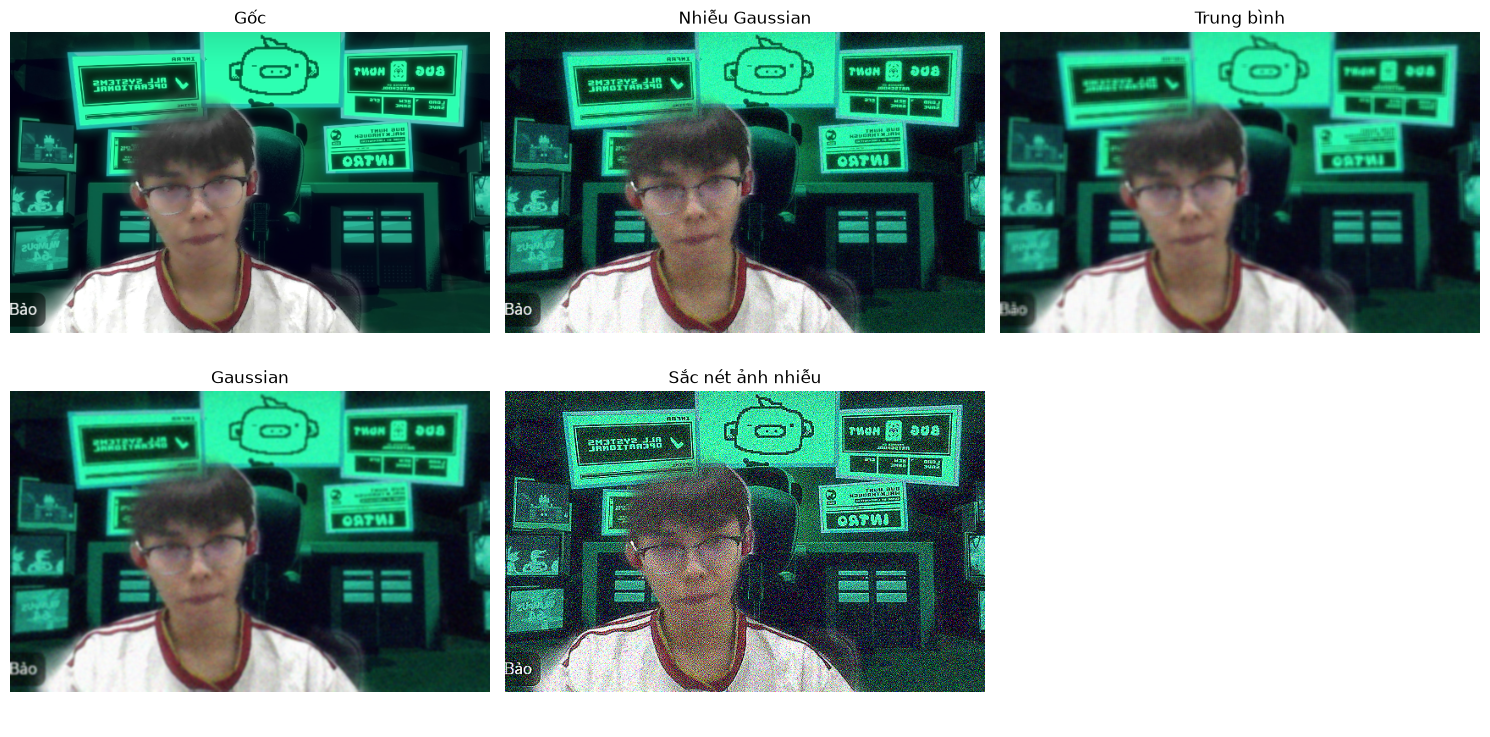

In [11]:
rng=np.random.default_rng(42)
noisy=to_uint8(image.astype(float)+rng.normal(0,15,image.shape))
show([('Gốc',image),('Nhiễu Gaussian',noisy),('Trung bình',mean_filter(noisy)),('Gaussian',gaussian_filter(noisy)),('Sắc nét ảnh nhiễu',sharpen(noisy))])

## 9. Lưu kết quả và tổng kết
Các bộ lọc tuyến tính ở bước tổng có trọng số; clip/làm tròn sau đó không tuyến tính. Tất cả kết quả lưu uint8. Thử thay ảnh, beta, alpha, T, kích thước kernel hoặc sigma rồi chạy lại để khảo sát.

In [12]:
OUT=LAB/'outputs'
OUT.mkdir(exist_ok=True)
for name,result in process(image).items():
    Image.fromarray(result).save(OUT/f'{name}.png')
print('Đã lưu 10 ảnh kết quả vào:',OUT)

Đã lưu 10 ảnh kết quả vào: E:\Các môn học năm 3\Thị giác máy tính\Lab_Elearning_Group_6_Computer_Vision\Lab_2.2\outputs
